# Neural Network Modeling
MGMT 47500: Machine Learning for Business · January–March 2026

Supervised autoencoder, expanding-window evaluation, and long–short decile portfolios.


In [ ]:
from pathlib import Path
from data import load_panel
from portfolio import long_short_decile_returns
output_dir = Path("artifacts")
output_dir.mkdir(exist_ok=True)
df = load_panel("data")
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1520078 entries, 0 to 1520077
Columns: 181 entries, permno to year
dtypes: category(1), datetime64[ns](1), float64(104), int64(1), int8(74)
memory usage: 1.3 GB


In [ ]:
import os
import math
import time
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from dataclasses import dataclass
from typing import List, Dict, Tuple, Optional

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# -----------------------------
# 1) Helper: Seed Everything
# -----------------------------
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE


'cpu'

In [ ]:
# ------------------------------------------------------------
# 2) Identify Feature Groups (characteristics / macro / industry)
# ------------------------------------------------------------
# Make sure df exists:
assert "df" in globals(), "Please load your DataFrame into variable `df` first."

# Ensure datetime
df = df.copy()
df["month"] = pd.to_datetime(df["month"])

id_cols = ["permno", "month", "year"]
target_col = "ret_excess"

char_cols = [c for c in df.columns if c.startswith("characteristic_")]
macro_cols = [c for c in df.columns if c.startswith("macro_")]
sic_cols  = [c for c in df.columns if c.startswith("sic2_")]

print("Num characteristics:", len(char_cols))
print("Num macro:", len(macro_cols))
print("Num industries:", len(sic_cols))
print("Total columns:", df.shape[1])

# Core design choice:
# - Autoencoder input = characteristics only
# - Optionally append macro later; for now keep it simple and clean.
X_cols = char_cols

# Basic sanity checks
assert target_col in df.columns
assert len(X_cols) > 0, "No characteristic_* columns found."


Num characteristics: 94
Num macro: 8
Num industries: 74
Total columns: 181


In [ ]:
# Month integer (1-12) from datetime month
df["month_num"] = df["month"].dt.month.astype(int)

# Unique month id (so we can rank within the SAME month)
df["ym_id"] = (df["year"].astype(int) * 100 + df["month_num"]).astype(int)

In [ ]:
df = df.dropna(subset=[target_col]).copy()

# You can optionally drop rows with too many missing features.
# We'll fill remaining feature NaNs with 0 (since characteristics are rank-transformed [-1,1]).
# Alternative: cross-sectional median fill per month (more finance-y). We'll do per-month median.
def fill_features_cs_median(data: pd.DataFrame, feature_cols: List[str]) -> pd.DataFrame:
    data = data.copy()
    # per-month median for each feature
    med = data.groupby("month")[feature_cols].transform("median")
    data[feature_cols] = data[feature_cols].fillna(med)
    # any remaining NaNs (month had all NaN): fill with 0
    data[feature_cols] = data[feature_cols].fillna(0.0)
    return data

df = fill_features_cs_median(df, X_cols)

# Sort to be safe
df = df.sort_values(["month", "permno"]).reset_index(drop=True)

print(df[["month", "permno", target_col]].head())
print(df[["month", "permno", target_col]].tail())
print("Rows after dropping NaN target:", len(df))


       month  permno  ret_excess
0 2001-02-01   10001   -0.016458
1 2001-02-01   10002    0.058700
2 2001-02-01   10012   -0.337133
3 2001-02-01   10016   -0.017350
4 2001-02-01   10019   -0.170467
             month  permno  ret_excess
1027676 2021-12-01   93397    0.030918
1027677 2021-12-01   93423    0.164242
1027678 2021-12-01   93426    0.081170
1027679 2021-12-01   93434   -0.065169
1027680 2021-12-01   93436   -0.076955
Rows after dropping NaN target: 1027681


In [ ]:
# Expanding time splits: train through t-2, validate t-1, test t.
years = sorted(df["year"].unique())
oos_years = [y for y in years if 2011 <= y <= 2021]


In [ ]:
# ----------------------------------------------------
# 5) Torch Dataset (tabular regression, big dataframe)
# ----------------------------------------------------
class PanelDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray, gid: np.ndarray=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

        if gid is None:
            self.gid = None
        else:
            self.gid = torch.tensor(gid, dtype=torch.long)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        if self.gid is None:
            return self.X[idx], self.y[idx]
        else:
            return self.X[idx], self.y[idx], self.gid[idx]


def make_loaders(train_df, val_df, feature_cols, target_col,
                 gid_col="ym_id", batch_size=4096, num_workers=0):

    X_train = train_df[feature_cols].to_numpy(dtype=np.float32)
    y_train = train_df[target_col].to_numpy(dtype=np.float32)
    g_train = train_df[gid_col].to_numpy(dtype=np.int64)

    X_val = val_df[feature_cols].to_numpy(dtype=np.float32)
    y_val = val_df[target_col].to_numpy(dtype=np.float32)
    g_val = val_df[gid_col].to_numpy(dtype=np.int64)

    train_ds = PanelDataset(X_train, y_train, g_train)
    val_ds = PanelDataset(X_val, y_val, g_val)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=(DEVICE=="cuda"))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=(DEVICE=="cuda"))
    return train_loader, val_loader


In [ ]:
# ---------------------------------------------------------
# 6) Supervised Autoencoder Model
# Input -> Encoder -> z (K factors)
# z -> Predictor -> y_hat
# Decoder: z -> reconstruction of input
# Loss combines prediction MSE, within-month ranking, and reconstruction MSE.
# ---------------------------------------------------------
class SupervisedAutoencoder(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, latent_dim: int, dropout: float = 0.1):
        super().__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
        )
        # Predictor head (simple linear = "factor returns" mapping)
        self.predictor = nn.Linear(latent_dim, 1)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, in_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        y_hat = self.predictor(z)
        x_hat = self.decoder(z)
        return y_hat, x_hat, z


In [ ]:
# ---------------------------------------------
# 7) Training Loop with Early Stopping
# ---------------------------------------------
@dataclass
class TrainConfig:
    hidden_dim: int = 64
    latent_dim: int = 8
    dropout: float = 0.2
    lr: float = 1e-3
    weight_decay = 5e-4
    epochs: int = 20
    batch_size: int = 4096

    # Loss weights
    alpha_mse = 0.5
    beta_rank = 0.5
    lambda_rec = 0.05   # small, regularizer

    # Early stopping on validation rank IC
    patience: int = 3

import torch
import torch.nn.functional as F

def pairwise_rank_loss(y_true, y_pred, group_id, n_pairs_per_group=256):
    """
    y_true, y_pred: shape [B]
    group_id: shape [B] month-id (same month -> same group)
    """
    loss_terms = []
    unique_g = torch.unique(group_id)
    for g in unique_g:
        idx = torch.where(group_id == g)[0]
        n = idx.numel()
        if n < 4:
            continue

        # sample random pairs inside this month
        i = idx[torch.randint(0, n, (n_pairs_per_group,), device=idx.device)]
        j = idx[torch.randint(0, n, (n_pairs_per_group,), device=idx.device)]

        yt_i, yt_j = y_true[i], y_true[j]
        yp_i, yp_j = y_pred[i], y_pred[j]

        s = torch.sign(yt_i - yt_j)  # +1 if i>j, -1 if i<j, 0 if tie
        mask = (s != 0)
        if mask.sum() < 10:
            continue

        diff = (yp_i - yp_j)[mask]
        s = s[mask]

        # logistic pairwise ranking loss
        loss_terms.append(torch.log1p(torch.exp(-s * diff)).mean())

    if len(loss_terms) == 0:
        return torch.tensor(0.0, device=y_true.device)
    return torch.stack(loss_terms).mean()

from sklearn.preprocessing import StandardScaler

def train_one_model(train_df, val_df, feature_cols, target_col, cfg: TrainConfig):
    # Scale features (fit on train only!)
    scaler = StandardScaler(with_mean=True, with_std=True)
    X_train = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
    X_val = scaler.transform(val_df[feature_cols].to_numpy(dtype=np.float32))

    train_scaled = train_df.copy()
    val_scaled = val_df.copy()
    train_scaled[feature_cols] = X_train
    val_scaled[feature_cols] = X_val

    train_loader, val_loader = make_loaders(
        train_scaled, val_scaled, feature_cols, target_col,
        gid_col="ym_id", batch_size=cfg.batch_size
    )

    model = SupervisedAutoencoder(
        in_dim=len(feature_cols),
        hidden_dim=cfg.hidden_dim,
        latent_dim=cfg.latent_dim,
        dropout=cfg.dropout
    ).to(DEVICE)

    optimizer = optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    mse = nn.MSELoss()

    best_ic = -1e9
    best_state = None
    bad_epochs = 0

    for epoch in range(1, cfg.epochs + 1):
        model.train()
        train_losses = []

        for xb, yb, gb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE).view(-1)
            gb = gb.to(DEVICE)

            optimizer.zero_grad()
            y_hat, x_hat, _ = model(xb)
            y_hat = y_hat.view(-1)

            loss_pred = mse(y_hat, yb)
            loss_rec = mse(x_hat, xb)
            loss_rank = pairwise_rank_loss(yb, y_hat, gb, n_pairs_per_group=256)

            loss = cfg.alpha_mse * loss_pred + cfg.beta_rank * loss_rank + cfg.lambda_rec * loss_rec
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        # --- Validation Rank IC (the metric you care about)
        model.eval()
        val_preds = []
        val_true = []
        val_year = []
        val_month = []

        with torch.no_grad():
            for xb, yb, _ in val_loader:
                xb = xb.to(DEVICE)
                y_hat, _, _ = model(xb)
                val_preds.append(y_hat.detach().cpu().numpy().reshape(-1))
                val_true.append(yb.detach().cpu().numpy().reshape(-1))

        val_preds = np.concatenate(val_preds)
        val_true = np.concatenate(val_true)

        tmp = val_scaled[["year", "month"]].copy()
        tmp["pred"] = val_preds
        tmp[target_col] = val_true
        val_ic = rank_ic_by_month(tmp, pred_col="pred", true_col=target_col)

        tr = float(np.mean(train_losses))
        print(f"Epoch {epoch:02d} | train loss {tr:.6f} | val rankIC {val_ic:.6f}")

        # Early stopping on Rank IC (maximize)
        if val_ic > best_ic + 1e-6:
            best_ic = val_ic
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg.patience:
                print("Early stopping on rank IC.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, scaler


In [ ]:
# ---------------------------------------------------------
# 8) Prediction Utility + OOS Metrics
# ---------------------------------------------------------
def predict_df(model, scaler, data_df, feature_cols, batch_size=8192):
    model.eval()
    X = scaler.transform(data_df[feature_cols].to_numpy(dtype=np.float32))
    ds = PanelDataset(
    X,
    data_df[target_col].to_numpy(dtype=np.float32),
    data_df["ym_id"].to_numpy(dtype=np.int64)
)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)

    preds = []
    zs = []
    with torch.no_grad():
        for xb, _, _ in loader:
            xb = xb.to(DEVICE)
            y_hat, _, z = model(xb)
            preds.append(y_hat.detach().cpu().numpy().reshape(-1))
            zs.append(z.detach().cpu().numpy())
    preds = np.concatenate(preds, axis=0)
    zs = np.concatenate(zs, axis=0)
    return preds, zs

def oos_r2(y_true, y_pred):
    # Out-of-sample R^2 relative to predicting the mean of y_true
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    sse = np.sum((y_true - y_pred) ** 2)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (sse / sst + 1e-12)

def rank_ic_by_month(df_monthly: pd.DataFrame, pred_col="pred", true_col=target_col):
    # Spearman correlation each (year, month), then average
    ics = []
    for (y, m), g in df_monthly.groupby(["year", "month"]):
        g = g.dropna(subset=[pred_col, true_col])
        if len(g) < 3 or g[true_col].nunique() < 3:
            continue
        ic = g[[pred_col, true_col]].corr(method="spearman").iloc[0, 1]
        if pd.notnull(ic):
            ics.append(ic)
    return float(np.mean(ics)) if len(ics) else np.nan


In [ ]:
# ---------------------------------------------------------
# 10) Baselines
#  (A) Ridge on raw features
#  (B) PCA factors + Ridge
#  (C) Simple MLP (no autoencoder)
# ---------------------------------------------------------
def fit_predict_ridge(train_df, test_df, feature_cols, alpha=5.0):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
    ytr = train_df[target_col].to_numpy(dtype=np.float32)
    Xte = scaler.transform(test_df[feature_cols].to_numpy(dtype=np.float32))

    model = Ridge(alpha=alpha, fit_intercept=True, random_state=42)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    return pred

def fit_predict_pca_ridge(train_df, test_df, feature_cols, n_components=8, alpha=5.0):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
    ytr = train_df[target_col].to_numpy(dtype=np.float32)
    Xte = scaler.transform(test_df[feature_cols].to_numpy(dtype=np.float32))

    pca = PCA(n_components=n_components, random_state=42)
    Ztr = pca.fit_transform(Xtr)
    Zte = pca.transform(Xte)

    model = Ridge(alpha=alpha, fit_intercept=True, random_state=42)
    model.fit(Ztr, ytr)
    pred = model.predict(Zte)
    return pred

class MLPRegressor(nn.Module):
    def __init__(self, in_dim, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )
    def forward(self, x):
        return self.net(x)

def train_predict_mlp(train_df, val_df, test_df, feature_cols,
                      hidden_dim=64, dropout=0.1, lr=1e-3, epochs=10, batch_size=4096):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(train_df[feature_cols].to_numpy(dtype=np.float32))
    Xva = scaler.transform(val_df[feature_cols].to_numpy(dtype=np.float32))
    Xte = scaler.transform(test_df[feature_cols].to_numpy(dtype=np.float32))

    ytr = train_df[target_col].to_numpy(dtype=np.float32)
    yva = val_df[target_col].to_numpy(dtype=np.float32)

    train_ds = PanelDataset(Xtr, ytr)
    val_ds = PanelDataset(Xva, yva)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    model = MLPRegressor(len(feature_cols), hidden_dim=hidden_dim, dropout=dropout).to(DEVICE)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    mse = nn.MSELoss()

    best_val = float("inf")
    best_state = None
    bad = 0
    patience = 2

    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb = xb.to(DEVICE); yb = yb.to(DEVICE)
            opt.zero_grad()
            yhat = model(xb)
            loss = mse(yhat, yb)
            loss.backward()
            opt.step()

        model.eval()
        losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE); yb = yb.to(DEVICE)
                yhat = model(xb)
                losses.append(mse(yhat, yb).item())
        va = float(np.mean(losses))
        print(f"MLP Epoch {ep:02d} | val {va:.6f}")

        if va < best_val - 1e-6:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    # predict test
    model.eval()
    with torch.no_grad():
        Xte_t = torch.tensor(Xte, dtype=torch.float32).to(DEVICE)
        pred = model(Xte_t).detach().cpu().numpy().reshape(-1)
    return pred


In [ ]:
# ---------------------------------------------------------
# 11) Full Expanding-Window Backtest Runner
# Produces:
# - out-of-sample predictions for each OOS year
# - OOS metrics: MSE, OOS R2, Rank-IC
# - out-of-sample predictions for decile portfolio evaluation
# ---------------------------------------------------------
from dataclasses import dataclass

@dataclass
class TrainConfig:
    hidden_dim: int = 64
    latent_dim: int = 8
    dropout: float = 0.2
    lr: float = 1e-3
    weight_decay: float = 5e-4
    epochs: int = 20
    batch_size: int = 4096

    alpha_mse: float = 0.5
    beta_rank: float = 0.5
    lambda_rec: float = 0.05

    patience: int = 3
cfg = TrainConfig(
    hidden_dim=64,
    latent_dim=8,
    dropout=0.2,
    lr=1e-3,
    weight_decay=5e-4,
    epochs=20,
    batch_size=4096,
    alpha_mse=0.5,
    beta_rank=0.5,
    lambda_rec=0.05,
    patience=3
)
all_oos_rows = []
metrics_rows = []

for test_year in oos_years:
    # Expanding train up to year-1
    train_df = df[df["year"] <= (test_year - 1)].copy()
    test_df  = df[df["year"] == test_year].copy()

    # Small validation: use last train year as val (to early stop)
    val_year = test_year - 1
    val_df = df[df["year"] == val_year].copy()
    train_sub = df[df["year"] <= (val_year - 1)].copy()

    # Guard: if too small, skip
    if len(train_sub) < 200000 or len(val_df) < 20000 or len(test_df) < 20000:
        print(f"Skipping year {test_year} due to small split sizes.")
        continue

    print("\n" + "="*70)
    print(f"Test Year: {test_year} | Train <= {val_year-1}, Val = {val_year}")
    print(f"Train rows: {len(train_sub):,} | Val rows: {len(val_df):,} | Test rows: {len(test_df):,}")

    # --- Train supervised autoencoder
    sae, scaler = train_one_model(train_sub, val_df, X_cols, target_col, cfg)

    # --- Predict test
    preds, zs = predict_df(sae, scaler, test_df, X_cols)
    test_out = test_df[["permno", "month", "year", target_col]].copy()
    test_out["pred_sae"] = preds
    all_oos_rows.append(test_out)

    # --- Baselines
    pred_ridge = fit_predict_ridge(train_sub, test_df, X_cols, alpha=5.0)
    test_out["pred_ridge"] = pred_ridge

    pred_pca = fit_predict_pca_ridge(train_sub, test_df, X_cols, n_components=cfg.latent_dim, alpha=5.0)
    test_out["pred_pca_ridge"] = pred_pca

    # MLP baseline (optional: can be slower)
    # For speed, use smaller epochs.
    pred_mlp = train_predict_mlp(train_sub, val_df, test_df, X_cols, epochs=6, hidden_dim=64)
    test_out["pred_mlp"] = pred_mlp

    # --- Metrics per model (on this test year)
    for name, pcol in [("SAE", "pred_sae"), ("Ridge", "pred_ridge"),
                       ("PCA+Ridge", "pred_pca_ridge"), ("MLP", "pred_mlp")]:
        y_true = test_out[target_col].to_numpy()
        y_pred = test_out[pcol].to_numpy()
        mse = mean_squared_error(y_true, y_pred)
        r2 = oos_r2(y_true, y_pred)

        tmp = test_out[["year", "month", target_col, pcol]].rename(columns={pcol: "pred"})
        ic = rank_ic_by_month(tmp, pred_col="pred", true_col=target_col)

        metrics_rows.append({
            "test_year": test_year,
            "model": name,
            "mse": mse,
            "oos_r2": r2,
            "rank_ic": ic
        })

    print(f"Finished year {test_year}.")

# Combine outputs
oos_df = pd.concat(all_oos_rows, axis=0).sort_values(["year", "month", "permno"]).reset_index(drop=True)
metrics_df = pd.DataFrame(metrics_rows)

metrics_df.head(), oos_df.head(), oos_df.tail()



Test Year: 2011 | Train <= 2009, Val = 2010
Train rows: 519,104 | Val rows: 47,934 | Test rows: 46,124
Epoch 01 | train loss 0.409968 | val rankIC 0.068621
Epoch 02 | train loss 0.399110 | val rankIC 0.067343
Epoch 03 | train loss 0.396478 | val rankIC 0.062967
Epoch 04 | train loss 0.395574 | val rankIC 0.070548
Epoch 05 | train loss 0.395198 | val rankIC 0.068913
Epoch 06 | train loss 0.395058 | val rankIC 0.067928
Epoch 07 | train loss 0.394844 | val rankIC 0.061779
Early stopping on rank IC.
MLP Epoch 01 | val 0.026091
MLP Epoch 02 | val 0.026009
MLP Epoch 03 | val 0.026130
MLP Epoch 04 | val 0.026123
Finished year 2011.

Test Year: 2012 | Train <= 2010, Val = 2011
Train rows: 567,038 | Val rows: 46,124 | Test rows: 44,544
Epoch 01 | train loss 0.406971 | val rankIC 0.105939
Epoch 02 | train loss 0.397208 | val rankIC 0.108939
Epoch 03 | train loss 0.395423 | val rankIC 0.090732
Epoch 04 | train loss 0.394922 | val rankIC 0.090124
Epoch 05 | train loss 0.394681 | val rankIC 0.0828

(   test_year      model       mse    oos_r2   rank_ic
 0       2011        SAE  0.022689 -0.026720  0.097300
 1       2011      Ridge  0.022386 -0.013009  0.004526
 2       2011  PCA+Ridge  0.022268 -0.007675  0.015118
 3       2011        MLP  0.022530 -0.019540  0.005039
 4       2012        SAE  0.021953 -0.030525  0.050570,
    permno      month  year  ret_excess  pred_sae  pred_ridge  pred_pca_ridge  \
 0   10001 2011-01-01  2011    0.028961  0.050480    0.021758        0.006890   
 1   10002 2011-01-01  2011    0.041099 -0.040985    0.013140        0.008093   
 2   10025 2011-01-01  2011    0.066952  0.010676    0.022823        0.018242   
 3   10026 2011-01-01  2011   -0.119710  0.024047    0.006279        0.014828   
 4   10028 2011-01-01  2011    0.032610  0.037786    0.007974        0.022474   
 
    pred_mlp  
 0  0.023668  
 1  0.024176  
 2  0.014616  
 3  0.023166  
 4  0.027587  ,
         permno      month  year  ret_excess  pred_sae  pred_ridge  \
 460638   93397 2021

In [ ]:
# ---------------------------------------------------------
# 12) Summarize Results Across Years
# ---------------------------------------------------------
summary = metrics_df.groupby("model").agg(
    mse_mean=("mse", "mean"),
    oos_r2_mean=("oos_r2", "mean"),
    rank_ic_mean=("rank_ic", "mean"),
    years=("test_year", "nunique")
).sort_values("rank_ic_mean", ascending=False)

summary


,mse_mean,oos_r2_mean,rank_ic_mean,years
model,,,,
SAE,0.034643,-0.036972,0.080381,11
Ridge,0.033771,-0.010766,0.009429,11
MLP,0.033806,-0.012341,0.004059,11
PCA+Ridge,0.033717,-0.008230,0.003583,11


In [ ]:
pred_cols = ["pred_sae", "pred_ridge", "pred_mlp", "pred_pca_ridge"]

results = []
ls_paths = {}

for pcol in pred_cols:
    tmp = oos_df[["year", "month", target_col, pcol]].rename(columns={pcol: "pred"})
    ls_df = long_short_decile_returns(tmp, pred_col="pred", ret_col=target_col,
                                      top_q=0.9, bot_q=0.1, min_n=30)

    mu = ls_df["long_short"].mean()
    sd = ls_df["long_short"].std()
    sharpe = mu / sd if sd > 0 else np.nan

    results.append({
        "model": pcol,
        "avg_monthly_long_short": mu,
        "std_long_short": sd,
        "sharpe_monthly": sharpe,
        "cum_long_short_end": ls_df["cum_long_short"].iloc[-1] if len(ls_df) else np.nan,
        "n_months": len(ls_df),
    })

    ls_paths[pcol] = ls_df

ls_summary = pd.DataFrame(results).sort_values("avg_monthly_long_short", ascending=False)
ls_summary

,model,avg_monthly_long_short,std_long_short,sharpe_monthly,cum_long_short_end,n_months
1,pred_ridge,0.011057,0.031893,0.346690,3.003088,132
2,pred_mlp,0.009372,0.032059,0.292342,2.208937,132
0,pred_sae,0.009036,0.074394,0.121458,1.202401,132
3,pred_pca_ridge,0.007731,0.042146,0.183439,1.464240,132


In [ ]:
# Cumulative long-short returns: top and bottom deciles (10% each).
import matplotlib.pyplot as plt
for name, path in ls_paths.items():
    path.to_csv(output_dir / f"{name}-monthly-deciles.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(path["month"], path["cum_long_short"])
    ax.set(title=f"{name}: cumulative long-short decile return", xlabel="Month", ylabel="Cumulative return")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_dir / f"{name}-cumulative.svg")
    plt.close(fig)


In [ ]:
# ---------------------------------------------------------
# 15) Interpretation: "What characteristics load onto each factor?"
# We approximate loadings using the first layer weights + encoder mapping.
#
# Simple, presentation-friendly approach:
# - Take the encoder's first linear layer weights: W1 (hidden_dim x in_dim)
# - Take second layer weights: W2 (latent_dim x hidden_dim)
# - Effective linear map from input -> latent: W_eff = W2 @ W1
#
# This is not exact due to ReLU, but it gives a clean "loading-like" story.
# You can show top characteristics per factor by |W_eff|.
# ---------------------------------------------------------
def encoder_effective_weights(model: SupervisedAutoencoder) -> np.ndarray:
    # encoder is [Linear, ReLU, Dropout, Linear]
    lin1 = model.encoder[0]
    lin2 = model.encoder[3]
    W1 = lin1.weight.detach().cpu().numpy()  # hidden x in
    W2 = lin2.weight.detach().cpu().numpy()  # latent x hidden
    W_eff = W2 @ W1  # latent x in
    return W_eff

# Fit through 2019; select the epoch on 2020; interpret the encoder.
val_full = df[df["year"] == 2020].copy()  # val = 2020, train <=2019
train_sub = df[df["year"] <= 2019].copy()

sae_final, scaler_final = train_one_model(train_sub, val_full, X_cols, target_col, cfg)

W_eff = encoder_effective_weights(sae_final)  # shape: (K, num_features)

K = W_eff.shape[0]
top_k = 10

factor_loading_tables = []
for k in range(K):
    w = W_eff[k]
    idx = np.argsort(np.abs(w))[::-1][:top_k]
    factor_loading_tables.append(pd.DataFrame({
        "factor": [k]*top_k,
        "characteristic": [X_cols[i] for i in idx],
        "weight": w[idx],
        "abs_weight": np.abs(w[idx])
    }))

loadings_df = pd.concat(factor_loading_tables, axis=0).reset_index(drop=True)
loadings_df.head(20)


Epoch 01 | train loss 0.403345 | val rankIC 0.011105
Epoch 02 | train loss 0.394210 | val rankIC 0.011853
Epoch 03 | train loss 0.393193 | val rankIC 0.004874
Epoch 04 | train loss 0.392757 | val rankIC 0.010566
Epoch 05 | train loss 0.392456 | val rankIC 0.013158
Epoch 06 | train loss 0.392289 | val rankIC 0.005361
Epoch 07 | train loss 0.392154 | val rankIC 0.008158
Epoch 08 | train loss 0.392052 | val rankIC 0.006758
Early stopping on rank IC.


,factor,characteristic,weight,abs_weight
0,0,characteristic_turn,0.172257,0.172257
1,0,characteristic_dolvol,0.145814,0.145814
2,0,characteristic_zerotrade,-0.142670,0.142670
3,0,characteristic_mvel1,0.123139,0.123139
4,0,characteristic_convind,0.110789,0.110789
5,0,characteristic_lev,0.101791,0.101791
6,0,characteristic_cfp,0.094822,0.094822
7,0,characteristic_cash,-0.090702,0.090702
8,0,characteristic_betasq,0.085900,0.085900
9,0,characteristic_ill,-0.084772,0.084772


In [ ]:
# ---------------------------------------------------------
# 16) Factor Time Series: "how factor importance changes over time"
# - Extract z (latent factors) each month for OOS
# - Create a monthly "factor return proxy" by regressing returns on z cross-sectionally
#   (each month separately): ret ~ z
# This yields factor premia time series.
# ---------------------------------------------------------
from sklearn.linear_model import LinearRegression

def monthly_factor_premia(test_df: pd.DataFrame, z: np.ndarray, y: np.ndarray, months: np.ndarray):
    """
    For each month, run cross-sectional regression: y = a + b'z
    Return b_t time series (factor premia).
    """
    res = []
    df_tmp = pd.DataFrame({"month": months, "y": y})
    for j in range(z.shape[1]):
        df_tmp[f"z{j}"] = z[:, j]

    for m, g in df_tmp.groupby("month"):
        if len(g) < 200:
            continue
        X = g[[f"z{j}" for j in range(z.shape[1])]].to_numpy()
        yy = g["y"].to_numpy()
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X, yy)
        b = reg.coef_
        res.append([m] + list(b))

    cols = ["month"] + [f"factor_{j}" for j in range(z.shape[1])]
    return pd.DataFrame(res, columns=cols).sort_values("month")

# Example: compute factor premia on 2021 using sae_final
test_2021 = df[df["year"] == 2021].copy()
pred_2021, z_2021 = predict_df(sae_final, scaler_final, test_2021, X_cols)
premia_2021 = monthly_factor_premia(test_2021, z_2021, test_2021[target_col].to_numpy(), test_2021["month"].to_numpy())
premia_2021.head()


,month,factor_0,factor_1,factor_2,factor_3,factor_4,factor_5,factor_6,factor_7
0,2021-01-01,0.267401,0.121830,0.015171,-0.000899,0.225622,-0.154417,-0.145981,-0.192226
1,2021-02-01,0.016399,-0.010427,-0.025493,0.006186,0.023843,0.000051,-0.019481,-0.016740
2,2021-03-01,-0.000656,-0.042043,-0.025692,-0.015277,-0.010501,0.030652,0.011026,0.003648
3,2021-04-01,-0.049365,-0.031967,-0.022866,-0.016933,-0.034219,0.017815,0.035156,0.039721
4,2021-05-01,0.014218,-0.019481,-0.025511,-0.009839,0.010084,0.000537,-0.016234,-0.009869


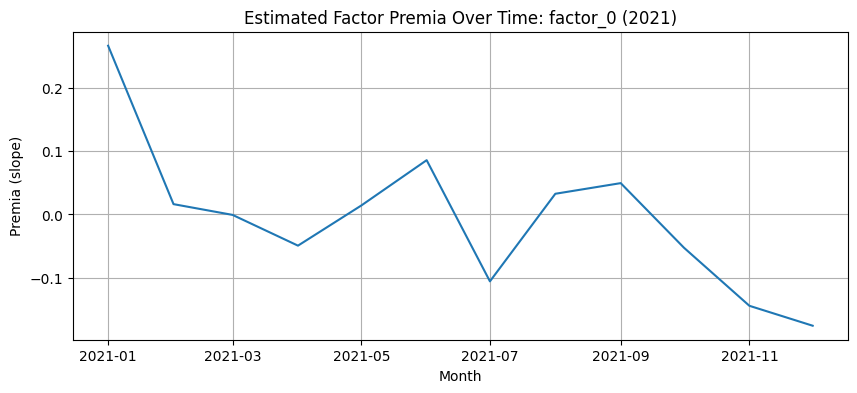

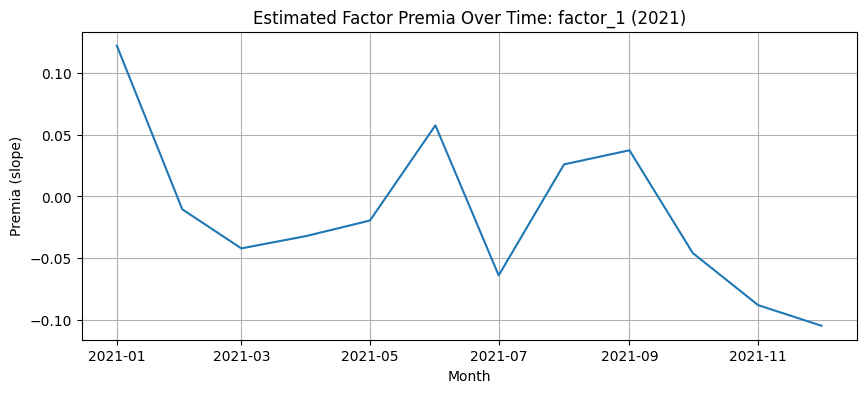

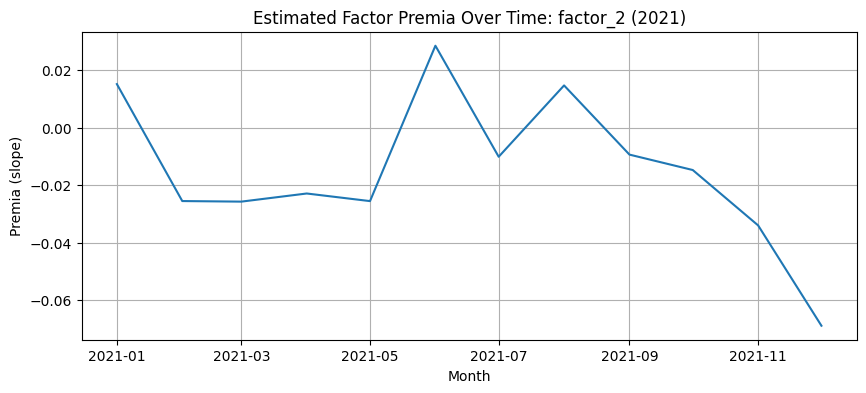

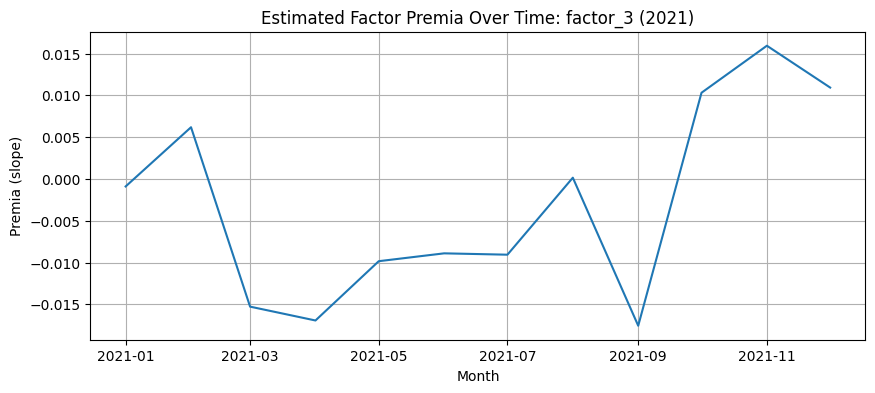

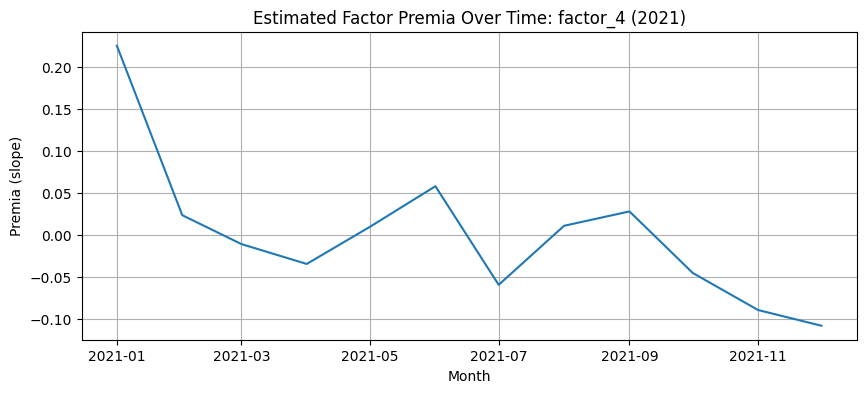

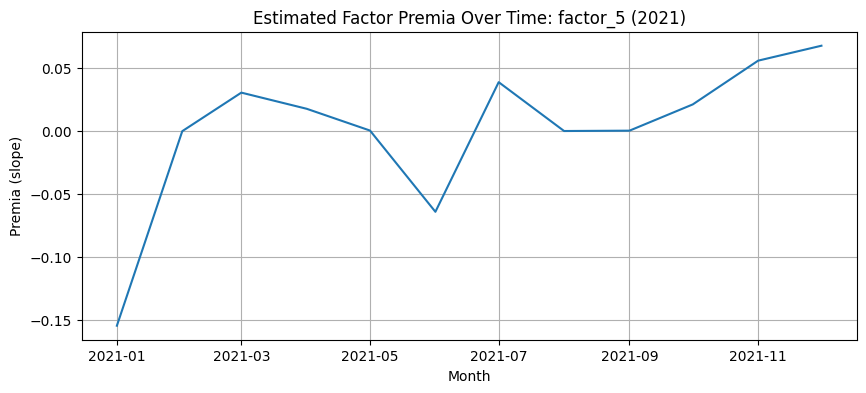

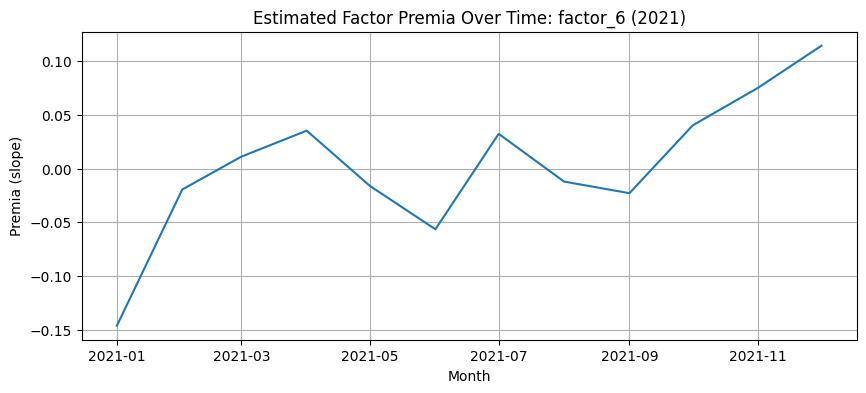

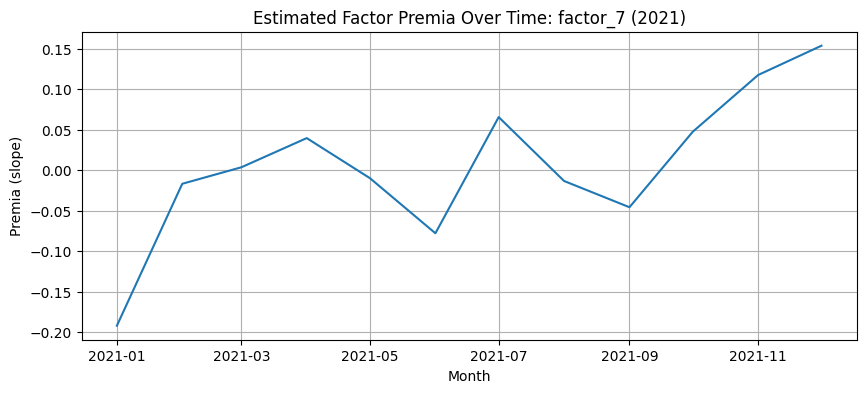

In [ ]:
# Plot factor premia time series (example)
if len(premia_2021) > 0:
    for col in premia_2021.columns:
        if col == "month":
            continue
        plt.figure(figsize=(10,4))
        plt.plot(premia_2021["month"], premia_2021[col])
        plt.title(f"Estimated Factor Premia Over Time: {col} (2021)")
        plt.xlabel("Month")
        plt.ylabel("Premia (slope)")
        plt.grid(True)
        plt.show()


In [ ]:
# Export model, portfolio, and interpretation tables.
summary.to_csv(output_dir / "model-comparison.csv")
metrics_df.to_csv(output_dir / "metrics-by-year.csv", index=False)
ls_summary.to_csv(output_dir / "decile-portfolios.csv", index=False)
loadings_df.to_csv(output_dir / "factor-loadings.csv", index=False)
premia_2021.to_csv(output_dir / "factor-premia-2021.csv", index=False)
print(f"Saved analysis outputs to {output_dir}")


AI Acknowledgement: I used ChatGPT feature in colab in helping me write code.